## Finding Roots of a Non-Linear Equation

Planck's radiation law tells us that the intensity of radiation per unit area and per unit wavelength $\lambda$ from a black body at temperature $T$ is:
$$  I(\lambda) = \frac{2\pi hc^2\lambda^{-5}} {e^{hc/\lambda k_BT}-1}$$
where $h$ is Planck's constant, $c$ is the speed of light, and $k_B$ is Boltzmann's constant.

By differentiating the above, we can show the wavelength $\lambda$ at which the emitted radiation is strongest is the solution of the equation:
$$ 5 e^{-hc/\lambda k_BT} + {hc\over\lambda k_BT} - 5 = 0$$
Making the substitution $x=hc/\lambda k_BT$, we can then show that the wavelength of maximum radiation obeys the "Wien displacement law":
$ \lambda = b / T$, where the "Wien displacement constant" is $b=hc/k_Bx$, and $x$ is the solution to the nonlinear equation: $$5e^{-x} +x - 5 = 0$$

We want to solve the nonlinear equation within (absolute) error $\epsilon = 10^{-6}$. Note, this function has two roots. One is at $x=0$. We want the other one, which is a positive real number.

### Exercise 1
Solve using binary search. 

(a) Use a function you write yourself "from scratch" that implements the algorithm and counts and how many iterations are required.

In [2]:
import numpy as np


In [7]:
import numpy as np
def eqn1(x): 
    return 5* np.exp(-x) + x -5

In [ ]:
def binarySearch(f, x1, x2, epsilon):
# x1, x2 upper and lower bracket values
# epsilon precision

    if f(x1)*f(x2) > 0.:
        raise NameError('Fct at brackets is of the same sign. Change brackets.')

    i = 0  # iterations counter
    while abs(x2-x1) > epsilon:
        i+= 1.0 
        midpoint= (x2+x1)/2.0
        if f(midpoint) == 0.0: 
            return midpoint
        if f(x1) * f(midpoint) < 0.0:
            x2 = midpoint
        else:
            x1 = midpoint 
    return (x1 + x2) / 2.0

lower_bound = 2.0
upper_bound = 6.0
precision = 1e-6

root = binarySearch(eqn1, lower_bound, upper_bound, precision)

print(f"The root is approx: {root:.6f}")


The root is approximately: 4.965114


(b) Use scipy.optimize.bisect

In [ ]:
import scipy.optimize as scopt
root= scopt.bisect(eqn1, a= 2, b= 6)
print(f"The root is approx: {root:.6f}")

The root is approximately: 4.965114


### Exercise 2
Solve using relaxation. Use a function you write yourself "from scratch" that implements the algorithm and counts and how many iterations are required.

In [ ]:
def eqn2(x):
    return  5 - 5 * np.exp(-x)

In [16]:
def eqn2(x):
    return 5* np.exp(-x) + x -5
def relaxationSearch(f, x1, x2, epsilon):
    list[float]
    guesses = [x1]
    if epsilon > 1:
        guess1 = f(x1)
        guesses.append(guess1)
    if epsilon > 2:
        guess2 = f(guess1)
        guesses.append(guess2)
    for i in range(epsilon - 3):
        guess3 = f(guesses[-1])
        den = 2 * guesses[-1] - guess3 - guesses[-2]
        if den == 0:
            den = 1e-14
            num = (guesses[-2] - guesses[-1]) ** 2
            epsilon = abs(num / den)
            guesses.append(guess3)
        if epsilon < x2:
            break
    return guesses


initial_guess = 5.0  
precision = 1e-6  
max_iterations = 50  
root_guesses = relaxationSearch(eqn2, initial_guess, precision, max_iterations)

print("Guesses:", root_guesses)
print("Final root approximation:", root_guesses[-1])

print(root)

Guesses: [5.0, np.float64(0.033689734995427045), np.float64(-0.13195304261544827)]
Final root approximation: -0.13195304261544827
4.965114231743428


### Exercise 3
Solve using Newton's Method. 

(a) Use a function you write yourself "from scratch" that implements the algorithm and counts and how many iterations are required.

In [ ]:
def df(x):
    return -5*np.exp(-x) + 1

def eqn1(x): 
    return 5* np.exp(-x) + x -5
    

In [ ]:
def df(x):
    return -5*np.exp(-x) + 1

def eqn1(x): 
    return 5* np.exp(-x) + x -5
def NewtonSearch(f, df, x1, epsilon, max_iterations= 100):
    xn = x1
    for n in range(0,max_iterations):
        fxn = f(xn)
        if abs(fxn) < epsilon:
            print('Found solution after',n,'iterations.')
            return xn
        Dfxn = df(xn)
        if Dfxn == 0:
            print('derivative is zero. No solution found.')
            return None
        xn = xn - fxn/Dfxn
    print('More than max iterations. No solution found.')
    return None

initial_guess = 2.0
tolerance = 1e-6

root = NewtonSearch(eqn1, df, initial_guess, tolerance)
print(f"Approximated Root: {root}")

Found solution after 4 iterations.
Approximated Root: 4.965114231750363


(b) Use scipy.optimize.root_scalar(method=’newton’)

In [29]:
import scipy.optimize as scopt
from scipy.optimize import newton
def df(x):
    return -5*np.exp(-x) + 1

def eqn1(x): 
    return 5* np.exp(-x) + x -5
root = newton(eqn1, x0 =2.0, fprime= df)
print(f"The root is approximately: {root:.6f}")

The root is approximately: 4.965114


### Exercise 4
Solve using Secant Method.

(a) Use a function you write yourself "from scratch" that implements the algorithm and counts and how many iterations are required.

In [33]:
def secantSearch(f, x1, x2, epsilon):
    x3 = x2 -f(x2) * (x2-x1)/(f(x2)-f(x1))
    i=1 
    while abs(x3-x2) > epsilon:
        i += 1
        if i>1000:
            raise NameError('convergence Error.')
        x1= x2
        x2 = x3
        x3 = x2 - f(x2)*(x2-x1)/(f(x2)-f(x1))
    return x2, 1
secantSearch(eqn1, 1.0, 1000., 1e-6)

(np.float64(4.96511422148082), 1)

(b) Use scipy.optimize.root_scalar(method=’secant’)

In [36]:
import scipy.optimize as scopt
from scipy.optimize import root_scalar

def eqn1(x): 
    return 5* np.exp(-x) + x -5
root = root_scalar(eqn1, method = 'secant', x0 = 4.0, xtol= 1e-6)
print(f"The root is approximately: {root}")

The root is approximately:       converged: True
           flag: converged
 function_calls: 5
     iterations: 4
           root: 4.965114231752864
         method: secant


## Bonus

(No marks, just for fun)  Try other method(s) in scipy.optimize to solve the problem.

## Exercise 5

An incandescent light bulb usually contains a metal filament that is thin enough so that an electrical current will heat it sufficiently to radiate thermally and visibly. Almost all of the power consumed by the bulb is radiated as blackbody radiation, with only a fraction of the radiation in the visible part of the spectrum. If the light bulb is assumed (somewhat inaccurately) to be a perfect blackbody, then the power radiated per unit wavelength $\lambda$ obeys
$$  I(\lambda) = \frac{2\pi\,Ahc^2}{\lambda^5 (e^{hc/\lambda\,k_bT} - 1)}$$
where $A$ is the surface area of the filament, $h$ is Planck's constant, $c$ is the speed of light, and $k_B$ is Boltzmann's constant. The total energy radiated between two wavelengths $\lambda_1$ and $\lambda_2$ is then
$$ E(\lambda_1,\lambda_2) = \int_{\lambda_1}^{\lambda_2} I(\lambda) d\lambda $$
and a lightbulb efficiency can be defined as the ratio of desirable light to the total energy emitted by the lightbulb:
$$\eta = \frac{E(\lambda_1,\lambda_2)}{E(0,\infty)}$$


(a) Write a  function to take the temperature T and estimate the efficiency $\eta$ of a lightbulb, for radiation between wavelengths $\lambda_{min},\lambda_{max}$. For this estimate, it's sufficient to use a $E$(very small number, very large number) rather than $E(0,\infty)$ in the denominator of the formula for $\eta$.


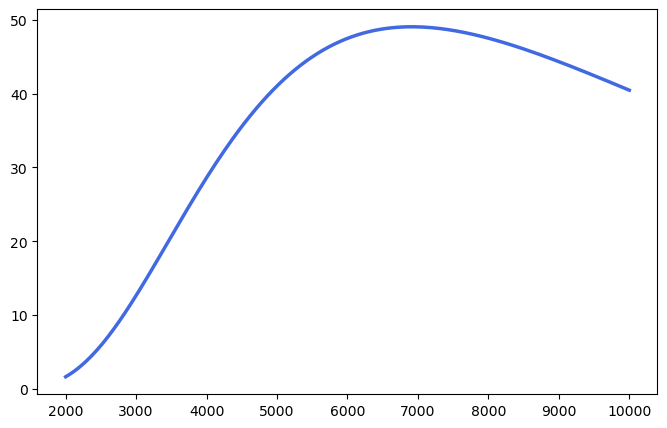

In [ ]:
import scipy.integrate as si
import scipy.constants as sc
from scipy.integrate import quad

def integrand(u):
    if u > 700:
        return 0.0
    return u**3 / (np.exp(u) - 1.0)

def planck(lam1, lam2, T):
    constant_factor = (sc.h * sc.c) / sc.k
    x1 = constant_factor / (T * lam2)
    x2 = constant_factor / (T * lam1)
    
    integral, _ = si.quad(integrand, x1, x2)
    return integral

def efficiency(T, lam1, lam2):
    num = planck(lam1, lam2, T)
    lam_very_small = 1e-9  # 1 nm
    lam_very_large = 1e-3  # 1 mm
    denom = planck(lam_very_small, lam_very_large, T)
    
    return num / denom

import matplotlib.pyplot as plt

T_axis = np.linspace(2000, 10000, 200)

lam1 = 380 * 1e-9
lam2 = 780 * 1e-9
efficiencies = [efficiency(T, lam1, lam2) * 100 for T in T_axis]

plt.figure(figsize=(8, 5))
plt.plot(T_axis, efficiencies, color='royalblue', lw=2.5, label='Efficiency $\eta(T)$')


(b) For $\lambda_{min},\lambda_{max}$ = 380nm, 780nm: calculate the temperature of maximum efficiency of the light bulb, using the search method of your choice

In [7]:
import scipy.constants as sc
import scipy.constants as const
from scipy.integrate import quad
import numpy as np

def d_efficiency_dT(T):
    dT = 1e-3  
    lam1 = 380 * 1e-9
    lam2 = 780 * 1e-9
    return (efficiency(T + dT, lam1, lam2) - efficiency(T - dT, lam1, lam2)) / (2 * dT)

def binarySearch(f, low, high, epsilon):
    if f(low) * f(high) > 0:
        raise ValueError("The maximum efficiency peak is not inside this range.")
        
    i = 0
    while (high - low) / 2.0 > epsilon:
        i += 1
        if i > 1000:
            raise RuntimeError('Max iterations exceeded.')
            
        mid = (low + high) / 2.0
        f_mid = f(mid)
        
        if abs(f_mid) < 1e-12: 
            return mid, i
    
        if f(low) * f_mid < 0:
            high = mid
        else:
            low = mid
            
    return (low + high) / 2.0, i

optimal_T, iterations = binarySearch(d_efficiency_dT, low=2000.0, high=10000.0, epsilon=1e-4)

print(f"Optimal T: {optimal_T:.2f} K")
print(f"Converged in {iterations} iterations.")


Optimal T: 6912.83 K
Converged in 26 iterations.
